# 01 · Data + TF-IDF/SVM baseline
**Owner: Mahbubul Alam** · Paper: *Zero-Shot vs. Fine-Tuned: A Cross-Dataset Study of LLMs and BanglaBERT for Bangla Fake News Detection*

This notebook (1) loads and cleans every dataset the same way all other notebooks do, (2) prints the dataset statistics table for the paper, and (3) trains the classical baseline: word + character TF-IDF features with a linear SVM.

**Kaggle settings for this notebook** (right-hand panel → *Session options*):
- **Accelerator:** None (CPU is enough)
- **Internet:** On (not needed)
- **Inputs** (*Add Input*): `hrithikmajumdar/bangla-fake-news` (BanFakeNews-2.0) and your team's `banglafakenews2025` dataset. If you also have `New_Test_Dataset.csv` (the 1,000-article external test set of BanFakeNews-2.0), add it too; it is detected automatically.

Label convention everywhere: **1 = Real, 0 = Fake**. Run once with `FAST_DEV_RUN = True` (a few minutes) to check everything works, then set it to `False` and use **Save Version → Save & Run All** so it runs in the background.

In [1]:
# ======================================================================
# COMMON DATA CODE  (identical in all 4 notebooks; if you change it,
# change it in every notebook, otherwise the example ids will not match)
# ======================================================================
import os, re, glob, json, random, hashlib, unicodedata, warnings
import numpy as np
import pandas as pd

SEED = 42
FAKE, REAL = 0, 1   # label convention everywhere (same as BanFakeNews-2.0 on Kaggle and BanglaFakeNews2025)

INPUT_DIR = os.environ.get('BFN_INPUT_DIR', '/kaggle/input')
OUT_DIR   = os.environ.get('BFN_OUT_DIR', '/kaggle/working')
PRED_DIR  = os.path.join(OUT_DIR, 'preds')
os.makedirs(PRED_DIR, exist_ok=True)

# Leave as None to auto-detect files under INPUT_DIR. Set a path (or a list of
# paths for bfn2025) only if auto-detection picks the wrong file.
PATHS = dict(
    bfn2_train=None, bfn2_val=None, bfn2_test=None,   # BanFakeNews-2.0 split files
    bfn2_all=None,                                    # ...or one single BanFakeNews-2.0 file
    bfn2_external=None,                               # New_Test_Dataset.csv (460 fake + 540 real)
    bfn2025=None,                                     # BanglaFakeNews2025 Bangla csv file(s)
)

LLM_SUBSET_SIZE  = 1000   # stratified sample of the BanFakeNews-2.0 test split used for ALL models
BFN2025_LLM_SIZE = 1000   # stratified sample of BanglaFakeNews2025 used for ALL models


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


_URL = re.compile(r'https?://\S+|www\.\S+')
_HTML = re.compile(r'<[^>]+>')
_WS = re.compile(r'\s+')

def clean_text(s):
    if not isinstance(s, str):
        s = '' if pd.isna(s) else str(s)
    s = unicodedata.normalize('NFC', s)
    s = _HTML.sub(' ', s)
    s = _URL.sub(' ', s)
    s = s.replace('\xa0', ' ')
    return _WS.sub(' ', s).strip()


_COLMAP = {'headline': 'Headline', 'title': 'Headline', 'heading': 'Headline',
           'content': 'Content', 'text': 'Content', 'article': 'Content', 'body': 'Content', 'news': 'Content',
           'label': 'Label', 'class': 'Label', 'target': 'Label',
           'category': 'Category', 'domain': 'Domain',
           'f-type': 'FType', 'f_type': 'FType', 'ftype': 'FType', 'fake_type': 'FType'}

def _std_cols(df, source):
    ren = {}
    for c in df.columns:
        k = str(c).strip().lower()
        if k in _COLMAP and _COLMAP[k] not in ren.values():
            ren[c] = _COLMAP[k]
    df = df.rename(columns=ren)
    missing = {'Content', 'Label'} - set(df.columns)
    if missing:
        raise ValueError(f'[{source}] columns {missing} not found. Columns are {list(df.columns)}. '
                         'Rename them or add them to _COLMAP.')
    if 'Headline' not in df.columns:
        df['Headline'] = ''
    return df


def _to_binary(df, source):
    lab = df['Label']
    if not pd.api.types.is_numeric_dtype(lab):
        low = lab.astype(str).str.strip().str.lower()
        m = {'real': REAL, 'authentic': REAL, 'true': REAL, '1': REAL,
             'fake': FAKE, 'false': FAKE, '0': FAKE}
        bad = set(low.unique()) - set(m)
        if bad:
            raise ValueError(f'[{source}] unknown label values {bad}')
        df['Label'] = low.map(m).astype(int)
        return df
    df = df[lab.notna()].copy()
    lab = df['Label'].astype(int)
    vals = set(lab.unique())
    if vals <= {0, 1}:
        df['Label'] = lab
        return df
    if vals == {0, 1, 2, 3}:
        # GitHub release of BanFakeNews-2.0: 3 = authentic, 0/1/2 = fake sub-types
        print(f'[{source}] 4-class labels found -> 3 = Real, 0/1/2 = Fake (sub-type kept in column FakeType)')
        df['FakeType'] = np.where(lab == 3, 'Not Applicable', 'type_' + lab.astype(str))
        df['Label'] = (lab == 3).astype(int)
        return df
    raise ValueError(f'[{source}] unexpected label values {vals}')


def _read(path):
    if path.lower().endswith(('.xlsx', '.xls')):
        return pd.read_excel(path)
    return pd.read_csv(path, encoding='utf-8-sig')


def _bangla_ratio(texts):
    s = ''.join(texts)[:50000]
    letters = [ch for ch in s if ch.isalpha() or 'ঀ' <= ch <= '৿']
    return sum('ঀ' <= ch <= '৿' for ch in letters) / max(1, len(letters))


def _prepare(df, source):
    df = _std_cols(df.copy(), source)
    df = _to_binary(df, source)
    df['Headline'] = df['Headline'].map(clean_text)
    df['Content'] = df['Content'].map(clean_text)
    n0 = len(df)
    df = df[(df['Headline'].str.len() + df['Content'].str.len()) >= 20].copy()
    df['key'] = (df['Headline'] + '||' + df['Content']).map(lambda s: hashlib.md5(s.encode('utf-8')).hexdigest())
    df = df.drop_duplicates('key')
    if n0 - len(df):
        print(f'[{source}] dropped {n0 - len(df)} empty or duplicate rows')
    for col in ['Category', 'FType']:   # tidy labels like 'Crime ', 'Miscellaneous\t', 'Entertainmen'
        if col in df.columns:
            v = df[col].astype(str).str.strip()
            names = set(v.unique())
            fix = {}
            for a in names:
                longer = [b for b in names if b != a and b.startswith(a) and len(b) - len(a) <= 2]
                if len(longer) == 1:
                    fix[a] = longer[0]
            df[col] = v.replace(fix)
    keep = [c for c in ['Headline', 'Content', 'Label', 'Category', 'Domain', 'FType', 'FakeType', 'key']
            if c in df.columns]
    return df[keep].reset_index(drop=True)


def _all_files():
    fs = []
    for ext in ('csv', 'xlsx', 'xls'):
        fs += glob.glob(os.path.join(INPUT_DIR, '**', f'*.{ext}'), recursive=True)
    # never treat our own prediction files as data
    return sorted(f for f in fs if os.sep + 'preds' + os.sep not in f)


def _locate():
    found = {k: v for k, v in PATHS.items() if v}
    if isinstance(found.get('bfn2025'), str):
        found['bfn2025'] = [found['bfn2025']]
    files = _all_files()
    base = lambda f: os.path.basename(f).lower()
    if 'bfn2_external' not in found:
        c = [f for f in files if re.search(r'new[ _-]?test', base(f))]
        if c:
            found['bfn2_external'] = c[0]
    if 'bfn2025' not in found:
        c = [f for f in files if '2025' in f.lower()]
        if c:
            found['bfn2025'] = c
    used = {found.get('bfn2_external')} | set(found.get('bfn2025') or [])
    rest = [f for f in files if f not in used]
    for split, keys in [('bfn2_train', ['train']), ('bfn2_val', ['val', 'valid', 'dev']), ('bfn2_test', ['test'])]:
        if split not in found:
            c = [f for f in rest if any(k in base(f) for k in keys)]
            if c:
                found[split] = c[0]
    have_splits = all(k in found for k in ['bfn2_train', 'bfn2_val', 'bfn2_test'])
    if not have_splits and 'bfn2_all' not in found:
        c = [f for f in rest if f not in found.values()]
        if c:
            found['bfn2_all'] = max(c, key=os.path.getsize)   # biggest remaining file
    return found


def _strat_flag(df, n):
    from sklearn.model_selection import train_test_split
    if n is None or n >= len(df):
        return np.ones(len(df), dtype=bool)
    idx, _ = train_test_split(np.arange(len(df)), train_size=n, stratify=df['Label'], random_state=SEED)
    flag = np.zeros(len(df), dtype=bool)
    flag[idx] = True
    return flag


def load_all():
    """Returns dict: train, val, bfn2_test, and (if found) bfn2_external, bfn2025."""
    from sklearn.model_selection import train_test_split
    f = _locate()
    print('Files used:')
    for k, v in f.items():
        print(f'  {k}: {v}')
    if all(k in f for k in ['bfn2_train', 'bfn2_val', 'bfn2_test']):
        tr, va, te = (_prepare(_read(f[k]), k) for k in ['bfn2_train', 'bfn2_val', 'bfn2_test'])
    elif 'bfn2_all' in f:
        alldf = _prepare(_read(f['bfn2_all']), 'bfn2_all')
        tr, tmp = train_test_split(alldf, test_size=0.30, stratify=alldf['Label'], random_state=SEED)
        va, te = train_test_split(tmp, test_size=0.50, stratify=tmp['Label'], random_state=SEED)
        print('One BanFakeNews-2.0 file found -> stratified 70/15/15 split with seed 42 (same ratio as the paper)')
    else:
        raise FileNotFoundError(f'BanFakeNews-2.0 not found under {INPUT_DIR}. Add it with "Add Input".')

    # no article may appear in both training data and any evaluation set
    seen = set(tr['key'])
    va = va[~va['key'].isin(seen)]
    te = te[~te['key'].isin(seen | set(va['key']))]
    data = {'train': tr, 'val': va, 'bfn2_test': te}

    if 'bfn2_external' in f:
        data['bfn2_external'] = _prepare(_read(f['bfn2_external']), 'bfn2_external')
    if 'bfn2025' in f:
        parts = []
        for p in f['bfn2025']:
            d = _std_cols(_read(p), p)
            r = _bangla_ratio(d['Content'].astype(str).head(200).tolist())
            if r < 0.5:
                print(f'  skipping {os.path.basename(p)} (not Bangla text, Bangla ratio {r:.2f})')
                continue
            parts.append(d)
        if parts:
            data['bfn2025'] = _prepare(pd.concat(parts, ignore_index=True), 'bfn2025')

    for name in ['bfn2_external', 'bfn2025']:
        if name in data:
            n0 = len(data[name])
            data[name] = data[name][~data[name]['key'].isin(seen)]
            if n0 - len(data[name]):
                print(f'[{name}] removed {n0 - len(data[name])} articles that also appear in the training split')

    for name, df in data.items():
        df = df.reset_index(drop=True)
        df.insert(0, 'id', [f'{name}_{i:05d}' for i in range(len(df))])
        data[name] = df
    data['bfn2_test']['in_llm_subset'] = _strat_flag(data['bfn2_test'], LLM_SUBSET_SIZE)
    if 'bfn2_external' in data:
        data['bfn2_external']['in_llm_subset'] = True
    if 'bfn2025' in data:
        data['bfn2025']['in_llm_subset'] = _strat_flag(data['bfn2025'], BFN2025_LLM_SIZE)

    print('\nSplit sizes (fake / total):')
    for name, df in data.items():
        print(f'  {name:14s} {int((df.Label == FAKE).sum()):6d} / {len(df):6d}')
    for k in ['bfn2_external', 'bfn2025']:
        if k not in data:
            print(f'  NOTE: {k} not found -> it will be skipped. Add it as an input to include it.')
    return data


def eval_sets(data, llm_only=False):
    """Evaluation sets. The *_llm sets are the shared subsets every model is compared on."""
    te = data['bfn2_test']
    out = {} if llm_only else {'bfn2_test': te}
    out['bfn2_test_llm'] = te[te['in_llm_subset']]
    if 'bfn2_external' in data:
        out['bfn2_external'] = data['bfn2_external']
    if 'bfn2025' in data:
        d = data['bfn2025']
        if not llm_only:
            out['bfn2025'] = d
        out['bfn2025_llm'] = d[d['in_llm_subset']]
    return {k: v.reset_index(drop=True) for k, v in out.items()}


def compute_metrics(y_true, y_pred, p_fake=None):
    from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                                 matthews_corrcoef, roc_auc_score, average_precision_score)
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    m = dict(n=int(len(y_true)), n_fake=int((y_true == FAKE).sum()),
             macro_f1=f1_score(y_true, y_pred, average='macro', labels=[FAKE, REAL], zero_division=0),
             fake_f1=f1_score(y_true, y_pred, pos_label=FAKE, zero_division=0),
             fake_precision=precision_score(y_true, y_pred, pos_label=FAKE, zero_division=0),
             fake_recall=recall_score(y_true, y_pred, pos_label=FAKE, zero_division=0),
             real_f1=f1_score(y_true, y_pred, pos_label=REAL, zero_division=0),
             accuracy=accuracy_score(y_true, y_pred),
             mcc=matthews_corrcoef(y_true, y_pred),
             pred_fake_rate=float((y_pred == FAKE).mean()))
    if p_fake is not None and len(set(y_true)) == 2:
        is_fake = (y_true == FAKE).astype(int)
        m['roc_auc'] = roc_auc_score(is_fake, p_fake)
        m['pr_auc_fake'] = average_precision_score(is_fake, p_fake)
    return {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in m.items()}


def _slug(s):
    return re.sub(r'[^A-Za-z0-9.+\-]+', '-', s).strip('-')


def report(model, setting, seed, set_name, df, y_pred, p_fake=None, extra=None):
    """Prints metrics, appends them to results.jsonl and saves per-article predictions."""
    m = compute_metrics(df['Label'].values, y_pred, p_fake)
    rec = dict(model=model, setting=setting, seed=int(seed), eval_set=set_name, **m, **(extra or {}))
    with open(os.path.join(OUT_DIR, 'results.jsonl'), 'a', encoding='utf-8') as fh:
        fh.write(json.dumps(rec, ensure_ascii=False) + '\n')
    out = pd.DataFrame({'id': df['id'].values, 'y_true': df['Label'].values,
                        'y_pred': np.asarray(y_pred).astype(int)})
    if p_fake is not None:
        out['p_fake'] = np.round(np.asarray(p_fake, dtype=float), 5)
    out.to_csv(os.path.join(PRED_DIR, f'{_slug(model)}__{setting}__{set_name}__seed{seed}.csv'), index=False)
    auc = f"  AUC={m['roc_auc']:.4f}" if 'roc_auc' in m else ''
    print(f"{model:24s} {setting:12s} seed={seed:<3d} {set_name:14s} n={m['n']:5d}  "
          f"macroF1={m['macro_f1']:.4f}  fakeF1={m['fake_f1']:.4f}{auc}")
    return rec

## 1. Load and clean all datasets

In [2]:
data = load_all()

Files used:
  bfn2025: ['/kaggle/input/datasets/mahbubulalamabid/banglafakenews2025/Bangla_Fake_News_Dataset.xlsx', '/kaggle/input/datasets/mahbubulalamabid/banglafakenews2025/Bangla_Real_News_Dataset.xlsx']
  bfn2_train: /kaggle/input/datasets/hrithikmajumdar/bangla-fake-news/train_cleaned.csv
  bfn2_val: /kaggle/input/datasets/hrithikmajumdar/bangla-fake-news/val_cleaned.csv
  bfn2_test: /kaggle/input/datasets/hrithikmajumdar/bangla-fake-news/test_cleaned.csv
[bfn2_train] 4-class labels found -> 3 = Real, 0/1/2 = Fake (sub-type kept in column FakeType)
[bfn2_train] dropped 1510 empty or duplicate rows
[bfn2_val] 4-class labels found -> 3 = Real, 0/1/2 = Fake (sub-type kept in column FakeType)
[bfn2_val] dropped 75 empty or duplicate rows
[bfn2_test] 4-class labels found -> 3 = Real, 0/1/2 = Fake (sub-type kept in column FakeType)
[bfn2_test] dropped 83 empty or duplicate rows
[bfn2025] dropped 8 empty or duplicate rows

Split sizes (fake / total):
  train            7243 /  40870
  v

## 2. Dataset statistics (Table: datasets)

In [3]:
rows = []
for name, df in data.items():
    words = (df['Headline'] + ' ' + df['Content']).str.split().str.len()
    rows.append(dict(split=name, articles=len(df), real=int((df.Label == REAL).sum()), fake=int((df.Label == FAKE).sum()),
                     fake_pct=round(100 * (df.Label == FAKE).mean(), 1),
                     median_words=int(words.median()), p95_words=int(words.quantile(0.95)),
                     in_llm_subset=int(df['in_llm_subset'].sum()) if 'in_llm_subset' in df else None))
summary = pd.DataFrame(rows)
summary.to_csv(os.path.join(OUT_DIR, 'dataset_summary.csv'), index=False)
display(summary)

,split,articles,real,fake,fake_pct,median_words,p95_words,in_llm_subset
0,train,40870,33627,7243,17.7,220,691,NaN
1,val,8370,7069,1301,15.5,220,698,NaN
2,bfn2_test,8259,7013,1246,15.1,218,695,1000.0
3,bfn2025,3992,1994,1998,50.1,175,634,1000.0


In [4]:
# Which fake sub-types / categories exist (useful for the error analysis later)
for name, df in data.items():
    for col in ['FakeType', 'FType', 'Category']:
        if col in df.columns:
            print(f'{name} · {col}:', df[col].value_counts().to_dict())

train · FakeType: {'Not Applicable': 33627, 'type_2': 4052, 'type_1': 1954, 'type_0': 1237}
val · FakeType: {'Not Applicable': 7069, 'type_2': 756, 'type_1': 368, 'type_0': 177}
bfn2_test · FakeType: {'Not Applicable': 7013, 'type_2': 709, 'type_1': 333, 'type_0': 204}
bfn2025 · FType: {'Not Applicable': 1994, 'Fabricated': 1416, 'Satire': 524, 'Altered': 30, 'Clickbaits': 28}
bfn2025 · Category: {'Politics': 788, 'Miscellaneous': 636, 'International': 538, 'Sports': 343, 'National': 316, 'Crime': 248, 'Entertainment': 217, 'Lifestyle': 192, 'Finance': 192, 'Education': 189, 'Technology': 178, 'Editorial': 155}


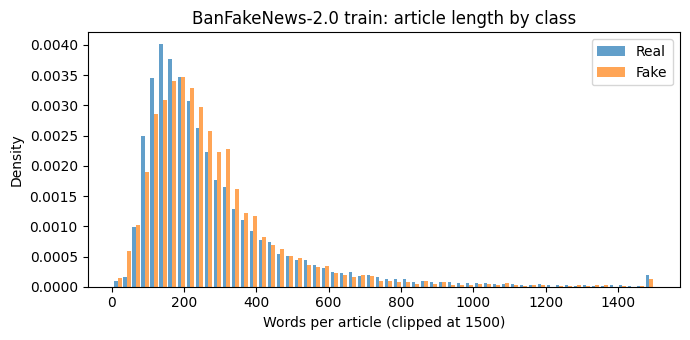

In [5]:
import matplotlib.pyplot as plt
tr = data['train']
words = (tr['Headline'] + ' ' + tr['Content']).str.split().str.len().clip(upper=1500)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist([words[tr.Label == REAL], words[tr.Label == FAKE]], bins=60, label=['Real', 'Fake'], stacked=False, density=True, alpha=0.7)
ax.set_xlabel('Words per article (clipped at 1500)'); ax.set_ylabel('Density'); ax.legend()
ax.set_title('BanFakeNews-2.0 train: article length by class')
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'length_hist.png'), dpi=200); plt.show()

## 3. TF-IDF + linear SVM baseline
Word 1–2-grams plus character 3–5-grams. `C` is tuned on the validation split only (never on test).

In [6]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score

FAST_DEV_RUN = False
SVM_MAX_CHARS = 3000          # characters of content used per article (keeps memory and time reasonable)
C_GRID = [0.01, 0.03, 0.05, 0.1, 0.3, 1.0]
BN_TOKEN = r'[\u0980-\u09FF\w]+'   # keeps Bangla vowel signs inside words

def svm_text(df):
    return (df['Headline'] + ' । ' + df['Content'].str.slice(0, SVM_MAX_CHARS)).tolist()

train_df, val_df = data['train'], data['val']
if FAST_DEV_RUN:
    train_df = train_df.sample(3000, random_state=SEED); val_df = val_df.sample(1000, random_state=SEED)

vec = FeatureUnion([
    ('word', TfidfVectorizer(analyzer='word', token_pattern=BN_TOKEN, ngram_range=(1, 2), min_df=2,
                             max_features=300_000, sublinear_tf=True, dtype=np.float32)),
    ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3,
                             max_features=300_000, sublinear_tf=True, dtype=np.float32)),
])
t0 = time.time()
X_train = vec.fit_transform(svm_text(train_df)); X_val = vec.transform(svm_text(val_df))
y_train, y_val = train_df['Label'].values, val_df['Label'].values
print(f'features: {X_train.shape[1]:,}  ({time.time() - t0:.0f}s)')

best = None
for C in C_GRID:
    clf = LinearSVC(C=C, class_weight='balanced', random_state=SEED, max_iter=5000).fit(X_train, y_train)
    f1 = f1_score(y_val, clf.predict(X_val), average='macro')
    print(f'C={C:<5}  val macro-F1={f1:.4f}')
    if best is None or f1 > best[0]:
        best = (f1, C, clf)
val_f1, best_C, svm = best
print(f'best C = {best_C} (val macro-F1 {val_f1:.4f})')

features: 600,000  (144s)
C=0.01   val macro-F1=0.8625
C=0.03   val macro-F1=0.8797
C=0.05   val macro-F1=0.8813
C=0.1    val macro-F1=0.8790
C=0.3    val macro-F1=0.8734
C=1.0    val macro-F1=0.8766
best C = 0.05 (val macro-F1 0.8813)


In [7]:
# Evaluate on every test set. p_fake is a sigmoid of the SVM margin (only used for AUC).
for name, df in eval_sets(data).items():
    if FAST_DEV_RUN:
        df = df.head(500)
    margin = svm.decision_function(vec.transform(svm_text(df)))   # > 0 means Real
    p_fake = 1 / (1 + np.exp(margin))
    y_pred = np.where(margin > 0, REAL, FAKE)
    report('TF-IDF+SVM', 'supervised', 0, name, df, y_pred, p_fake, extra={'C': best_C})

TF-IDF+SVM               supervised   seed=0   bfn2_test      n= 8259  macroF1=0.8820  fakeF1=0.7997  AUC=0.9568
TF-IDF+SVM               supervised   seed=0   bfn2_test_llm  n= 1000  macroF1=0.8644  fakeF1=0.7687  AUC=0.9376
TF-IDF+SVM               supervised   seed=0   bfn2025        n= 3992  macroF1=0.8317  fakeF1=0.8265  AUC=0.9089
TF-IDF+SVM               supervised   seed=0   bfn2025_llm    n= 1000  macroF1=0.8428  fakeF1=0.8380  AUC=0.9043


In [8]:
# Save the ids of the shared evaluation subsets (for the appendix / reproducibility)
ids = pd.concat([df.loc[df['in_llm_subset'], ['id', 'Label']] for k, df in data.items() if 'in_llm_subset' in df])
ids.to_csv(os.path.join(OUT_DIR, 'shared_eval_subset_ids.csv'), index=False)
print(len(ids), 'ids saved. Outputs:', sorted(os.listdir(OUT_DIR)))

2000 ids saved. Outputs: ['__notebook__.ipynb', 'dataset_summary.csv', 'length_hist.png', 'preds', 'results.jsonl', 'shared_eval_subset_ids.csv']
